# Imports

In [235]:
import sys
import seaborn as sns
import os
import random
import math
import torch
import pandas as pd
import asyncio
import numpy as np
from tqdm.auto import tqdm
from torch import Tensor
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
sys.path.append('..')
from definitions import EXPERIMENTS_DIR
from src.commands.train import Trainer, Config as TrainerConfig
from src.gnn import HetModel, HetModelReturn
from typing import List, Dict, Optional, Tuple
from itertools import batched
from src.commands.feature_extraction import Graph, Node, EdgeType, Edge, FeatureExtractor, _slugify
from src.helpers import make_openai_request, load_json_file
from openai import AsyncClient
from src.env import env, LLM
from torch_geometric import utils as gnn_utils
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    hamming_loss
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Utilities

In [2]:
def get_neighbor_triples(
    data : Graph,
    node_type : str,
    node_ids : List[str],
    nodes : Optional[List[str]] = None
) -> Dict[EdgeType, List[Node]]:
    
    graph = data.pygeo
    node_idx = torch.tensor([data._nodes[node_type]._id2idx[node_id] for node_id in node_ids])
    
    def _include_edge(edge : str) -> bool:

        src, e_type, dst = edge

        included_nodes = nodes if nodes is not None else graph.node_types
        
        return (src == node_type and dst in included_nodes) or (dst == node_type and src in included_nodes)
    
    edges = list(filter(_include_edge, graph.edge_types))

    neighbors = {}

    for src, e_type, dst in edges:

        edge_index : Tensor = graph[src, e_type, dst].edge_index
        src_idx, dst_idx = edge_index
        
        if src == node_type:
            neighbors_indices = torch.argwhere(torch.isin(src_idx, node_idx)).flatten().tolist()
        else:
            neighbors_indices = torch.argwhere(torch.isin(dst_idx, node_idx)).flatten().tolist()

        edge_pool = data._edges[EdgeType(src, dst, e_type)]._edges
        neighbors[(src, e_type, dst)] = [edge_pool[i] for i in neighbors_indices]

    return neighbors

# Load Expertise Map

In [3]:
domains = load_json_file('/home/fellah-a/Documents/Text2KG/resources/fields/industry_of_future/domains.json')
domains = { domain['sub_domain'] : domain['definition'] for domain in domains }

In [4]:
graph = Graph.load('/home/fellah-a/Documents/Text2KG/data/expertise_maps/nantes_uni_2020_2026_e5-v3')

In [5]:
graph_pygeo = graph.pygeo

# Entity Typing

In [6]:
in_degrees, out_degrees = graph.degrees[FeatureExtractor.Entity_HASRELATIONWITH_Entity]
degrees = in_degrees.copy()
degrees.update(out_degrees)
subset = [entity for entity, degree in degrees.items() if degree >= 15 and degree <= 35 ]
len(subset)

835

In [7]:
PROMPT = """
You are an expert in industrial innovation, knowledge graphs, and technology classification.

Your task is to classify a target entity into the specific Domain defined by its name and definition.

IMPORTANT RULES:

1. Focus on the intrinsic meaning, capabilities, and role of the target entity.
2. Use the provided knowledge graph triples as the primary source of evidence.

You are given:

* Domains' name.
* Domains Definition.
* A target entity
* Knowledge graph triples involving the entity
* Optional textual evidence

Available Domains and Sub-Domains:

Domain Name:
{domain_name}

Domain Definition:
{domain_definition}

Target Entity:
{entity}

Knowledge Graph Triples:
{triples}

Instructions:

1. Analyze the triples to determine the entity's function, purpose, technology area, and industrial role.
2. Compare the entity against the provided Domain and Sub-Domain definitions.
3. Select the best matching Domain and Sub-Domain.
4. Explain your reasoning using specific triples and evidence.
5. Provide a confidence score between 0 and 10.

### Output format :

    - Output : A Number between 0 and 10.
    - Output should be directly convertable to float.
    - No additional explanation , entity or domain name should be present in the output.
"""

In [8]:
async def llm_classify_entity(
    client : AsyncClient, 
    model : str,
    entity : str, 
    triples : List[Edge], 
    domain_name : str,
    domain_definition : str
) -> float:

    messages = [
        {
            "role" : "user",
            "content" : PROMPT.format(
                domain_name=domain_name,
                domain_definition=domain_definition,
                entity = entity,
                triples=[f'{e.src} -> {e.properties['predicate']} -> {e.dst}' for e in triples]
            )
        }
    ]

    response = await make_openai_request(
        client=client,
        model=model,
        messages=messages,
    )

    return response.unwrap().choices[0].message.content

In [9]:
async def classify_entities(
    llms : Dict[str, LLM],
    trials : int,
    subset : List[str],
    domains : Dict[str, str],
    batch_size : int
) -> pd.DataFrame:
    
    tasks = []

    for entity in subset:

        triples = get_neighbor_triples(graph, ('Entity',entity), ['Entity'])
        triples = triples[('Entity', 'HASRELATIONWITH', 'Entity')]

        for domain, domain_definition in domains.items():

            for trial in range(trials):
                    
                for llm in llms.values():

                    tasks.append({
                        "llm" : llm,
                        "entity" : entity,
                        "triples" : triples,
                        "domain" : domain,
                        "domain_definition" : domain_definition,
                        "trial" : trial
                    })

    all_results = []

    with tqdm(total=len(tasks)) as pbar:

        for batch in batched(tasks, batch_size):


            results = await asyncio.gather(*[
                llm_classify_entity(
                    client=task['llm'].async_client,
                    model=task['llm'].info.name,
                    entity=task['entity'],
                    triples=task['triples'],
                    domain_name=task['domain'],
                    domain_definition=task['domain_definition']
                )
                for task in batch
            ])

            all_results.extend([
                {
                    "model" : task['llm'].info.name, 
                    "entity" : task['entity'],
                    "domain" : task['domain'],
                    "trial" : task['trial'],
                    "score" : result
                } 
                for task, result in zip(batch, results)
            ])

            pbar.update(len(batch))

    return pd.DataFrame(all_results)

In [29]:
results = await classify_entities(
    llms={ 'deepseek-v4-flash' : env.llms['deepseek-v4-flash'] },
    trials=1,
    subset=subset,
    domains=domains,
    batch_size=32
)

100%|██████████| 15030/15030 [1:06:59<00:00,  3.74it/s]


In [10]:
results = pd.read_csv('./entities_deepseek-v4-pro.csv')

In [11]:
def _to_float(n : str) -> float | None:

    try:
        return float(n)
    except:
        return None

In [12]:
results['score_float'] = results['score'].apply(_to_float)
results = results.dropna()

In [13]:
results_p = results.drop(columns='trial').groupby(by=['model', 'entity']).agg(list).drop(columns='score')
results_p = results_p.apply(lambda x : dict(zip(x['domain'], x['score_float'])), axis=1)
results_p = pd.DataFrame(results_p.tolist(), index=results_p.index).reset_index()
results_p.columns = results_p.columns.map(_slugify)
results_p = results_p.set_index('entity')

In [14]:
results_p.head()

,model,robotics,processes_and_assembly,additive_manufacturing,monitoring_and_analysis,eco-design,reduction_and_treatment_of_effluents_and_waste,recycling_/_reuse,eco-responsible_processes,decarbonization_of_mobility,decarbonization_of_energy,composites_and_new_materials,industrial_digitalization,digital_engineering_of_products_and_processes,industrial_organization_performance,preparation_for_new_jobs_in_the_future_industry,change_management,user-centered_design,augmentation_of_human_capabilities_in_manufacturing
entity,,,,,,,,,,,,,,,,,,,
abstract_statistical_process_monitoring,deepseek-v4-flash,10.0,9.0,1.0,9.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,9.0,9.0,8.0,0.0,0.0,0.0,0.0
acceleration,deepseek-v4-flash,9.0,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0
access_point,deepseek-v4-flash,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0
acoustic_emission,deepseek-v4-flash,0.0,1.0,2.0,9.2,0.0,0.0,0.0,0.0,0.0,0.0,6.0,9.0,4.0,0.0,0.0,0.0,0.0,0.0
act,deepseek-v4-flash,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,7.0,9.0,0.0,0.0,0.0,0.0,0.0


# Inference

In [15]:
EXP = 'nantes-uni-2020_e5'
EXP_DIR = os.path.join(EXPERIMENTS_DIR, EXP)
MODELS_DIR = os.path.join(EXP_DIR, 'models')

In [16]:
### Domains
trainer_cfg = TrainerConfig(experiment=EXP)
trainer     = Trainer(experiment=trainer_cfg.experiment, config=trainer_cfg.training_config)
configs     = trainer.get_configs()

models : Dict[str, HetModel] = {}

for i,(conf_name, run_config) in enumerate(configs.items()):

    print(f"Loading {conf_name}")

    # Load data through the trainer (handles normalisation)
    if i == 0:
        data , _ = trainer.load_data(return_raw=True)

    # model
    model = trainer.create_model(config=run_config, data=data)
    state_dict = torch.load(os.path.join(MODELS_DIR, f'model_{conf_name}.pt'), weights_only=False, map_location="cpu")
    model.load_state_dict(state_dict)

    models[conf_name] = model

Loading Conv_Mean_null_False
Loading Conv_Max_null_False
Loading Conv_Attn_null_False


In [20]:
predictions : Dict[str, Tensor] = {}

for model_name, model in models.items():

    print(f"Inference {model_name}")

    model = model.eval().cpu()
    data  = data.cpu()
    model.ssl     = False
    model.cluster = False

    with torch.inference_mode():

        (row, col), _ = gnn_utils.add_remaining_self_loops(data['Entity', 'HASRELATIONWITH', 'Entity'].edge_index)
        out = model.forward(data)

        predictions[model_name] = out.entities_predictions['subdomain']

        predictions[f'{model_name}_v2'] = model.heads['subdomain'](model.readout_fn.forward(
            x = torch.cat([out.entities_embeddings[col],out.entities_embeddings[row]], dim=0),
            index = torch.cat([row, col], dim=-1),
            dim_size = out.entities_embeddings.shape[0],
            dim = 0
        ))

Inference Conv_Mean_null_False
Inference Conv_Max_null_False
Inference Conv_Attn_null_False


In [36]:
domains_per_entity = pd.Series(
    data=predictions['Conv_Mean_null_False'].sigmoid().gt(0.5).float().sum(dim=-1),
    index=list(graph._nodes['Entity']._id2idx.keys())
)

# Baseline

In [17]:
knn = Pipeline([
    ('Preprocessing', StandardScaler()),
    ('Estimator', KNeighborsClassifier()),
])

knn.fit(data['Article'].x_passage, data['Article'].y_subdomain)

P = knn.predict_proba(data['Entity'].x)

P = torch.from_numpy(np.stack([i[:,1] for i in P], axis=0).T)

# Evaluation

In [21]:
def evaluate_multilabel(
    model_df: pd.DataFrame,
    llm_df: pd.DataFrame,
    model_threshold: float = 0.5,
    llm_threshold: float = 5.0
) -> Tuple[pd.DataFrame, pd.DataFrame]:

    if not model_df.columns.equals(llm_df.columns):
        raise ValueError("Both dataframes must have identical columns")

    labels = model_df.columns.tolist()

    # Ground truth
    y_true = (llm_df >= llm_threshold).astype(int).values

    # Model outputs
    y_score = model_df.values
    y_pred = (y_score >= model_threshold).astype(int)

    # ---------- Overall metrics ----------

    overall = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "F1_Micro": f1_score(
            y_true,
            y_pred,
            average="micro",
            zero_division=0
        ),
        "F1_Macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Hamming_Loss": hamming_loss(
            y_true,
            y_pred
        )
    }

    try:
        overall["AUC_Micro"] = roc_auc_score(
            y_true,
            y_score,
            average="micro"
        )
    except ValueError:
        overall["AUC_Micro"] = np.nan

    try:
        overall["AUC_Macro"] = roc_auc_score(
            y_true,
            y_score,
            average="macro"
        )
    except ValueError:
        overall["AUC_Macro"] = np.nan

    overall_metrics = pd.DataFrame(
        [overall]
    )

    # ---------- Per-label metrics ----------

    rows = []

    for idx, label in enumerate(labels):

        yt = y_true[:, idx]
        yp = y_pred[:, idx]
        ys = y_score[:, idx]

        row = {
            "Label": label,
            "Accuracy": accuracy_score(yt, yp),
            "F1": f1_score(
                yt,
                yp,
                zero_division=0
            )
        }

        try:
            row["AUC"] = roc_auc_score(
                yt,
                ys
            )
        except ValueError:
            row["AUC"] = np.nan

        rows.append(row)

    per_label_metrics = pd.DataFrame(rows)

    return overall_metrics, per_label_metrics

In [ ]:
thresholds = np.arange(0.5, 1.0, 0.05).tolist()

overall_metrics = []
per_label_metrics = []

for model_name, preds in predictions.items():

    print(f"Evaluating model {model_name}")

    pred_df = pd.DataFrame(
        data=preds.sigmoid(), #preds['subdomain'].sigmoid() if model_name != "baseline" else preds['subdomain'],
        columns=[n.id for n in graph._nodes['SubDomain']._nodes],
        index=list(graph._nodes['Entity']._id2idx.keys())
    )

    predictions_subset = pred_df[results_p.columns[1:]].loc[results_p.index]
    pred_df.head()

    for threshold in thresholds:
        
        overall_metrics_th, per_label_metrics_th = evaluate_multilabel(
            predictions_subset,
            results_p[predictions_subset.columns],
            model_threshold=threshold,
            llm_threshold=5.0
        )

        overall_metrics_th['threshold']= threshold
        per_label_metrics_th['threshold']= threshold
        overall_metrics_th['model']= model_name
        per_label_metrics_th['model']= model_name

        overall_metrics.append(overall_metrics_th)
        per_label_metrics.append(per_label_metrics_th)

overall_metrics = pd.concat(overall_metrics)
per_label_metrics = pd.concat(per_label_metrics)

Evaluating model Conv_Mean_null_False
Evaluating model Conv_Mean_null_False_v2
Evaluating model Conv_Max_null_False
Evaluating model Conv_Max_null_False_v2
Evaluating model Conv_Attn_null_False
Evaluating model Conv_Attn_null_False_v2


In [55]:
overall_metrics.query('threshold == 0.5')

,Accuracy,F1_Micro,F1_Macro,Hamming_Loss,AUC_Micro,AUC_Macro,threshold,model
0,0.069461,0.473237,0.421104,0.165003,0.813842,0.811150,0.5,Conv_Mean_null_False
0,0.146108,0.533886,0.479411,0.104790,0.877058,0.868745,0.5,Conv_Mean_null_False_v2
0,0.165269,0.392510,0.336307,0.112242,0.796499,0.807731,0.5,Conv_Max_null_False
0,0.136527,0.549145,0.469571,0.112309,0.885667,0.868577,0.5,Conv_Max_null_False_v2
0,0.124551,0.503092,0.431332,0.117631,0.829371,0.823321,0.5,Conv_Attn_null_False
0,0.117365,0.499857,0.433098,0.116101,0.859970,0.837919,0.5,Conv_Attn_null_False_v2


In [56]:
overall_metrics.query("model == 'Conv_Mean_null_False'")

,Accuracy,F1_Micro,F1_Macro,Hamming_Loss,AUC_Micro,AUC_Macro,threshold,model
0,0.069461,0.473237,0.421104,0.165003,0.813842,0.81115,0.50,Conv_Mean_null_False
0,0.074251,0.476815,0.426077,0.159148,0.813842,0.81115,0.55,Conv_Mean_null_False
0,0.077844,0.480144,0.432102,0.153293,0.813842,0.81115,0.60,Conv_Mean_null_False
0,0.081437,0.480872,0.435548,0.148969,0.813842,0.81115,0.65,Conv_Mean_null_False
0,0.083832,0.480572,0.433851,0.144977,0.813842,0.81115,0.70,Conv_Mean_null_False
0,0.089820,0.480609,0.435572,0.140785,0.813842,0.81115,0.75,Conv_Mean_null_False
0,0.095808,0.478737,0.428505,0.136194,0.813842,0.81115,0.80,Conv_Mean_null_False
0,0.102994,0.478261,0.429211,0.130938,0.813842,0.81115,0.85,Conv_Mean_null_False
0,0.114970,0.476641,0.431200,0.125216,0.813842,0.81115,0.90,Conv_Mean_null_False
0,0.135329,0.467062,0.421859,0.119494,0.813842,0.81115,0.95,Conv_Mean_null_False


In [57]:
overall_metrics.query("model == 'Conv_Mean_null_False_v2'")

,Accuracy,F1_Micro,F1_Macro,Hamming_Loss,AUC_Micro,AUC_Macro,threshold,model
0,0.146108,0.533886,0.479411,0.104790,0.877058,0.868745,0.50,Conv_Mean_null_False_v2
0,0.147305,0.524342,0.469850,0.104657,0.877058,0.868745,0.55,Conv_Mean_null_False_v2
0,0.152096,0.521391,0.465350,0.103460,0.877058,0.868745,0.60,Conv_Mean_null_False_v2
0,0.152096,0.512610,0.449780,0.102861,0.877058,0.868745,0.65,Conv_Mean_null_False_v2
0,0.152096,0.504499,0.432202,0.102595,0.877058,0.868745,0.70,Conv_Mean_null_False_v2
0,0.150898,0.489285,0.412149,0.103061,0.877058,0.868745,0.75,Conv_Mean_null_False_v2
0,0.161677,0.478921,0.392922,0.102794,0.877058,0.868745,0.80,Conv_Mean_null_False_v2
0,0.166467,0.465165,0.380168,0.102661,0.877058,0.868745,0.85,Conv_Mean_null_False_v2
0,0.176048,0.448006,0.360814,0.103127,0.877058,0.868745,0.90,Conv_Mean_null_False_v2
0,0.186826,0.413149,0.328932,0.104524,0.877058,0.868745,0.95,Conv_Mean_null_False_v2


In [58]:
overall_metrics.query("model == 'Conv_Max_null_False'")

,Accuracy,F1_Micro,F1_Macro,Hamming_Loss,AUC_Micro,AUC_Macro,threshold,model
0,0.165269,0.392510,0.336307,0.112242,0.796499,0.807731,0.50,Conv_Max_null_False
0,0.166467,0.390654,0.335004,0.111045,0.796499,0.807731,0.55,Conv_Max_null_False
0,0.167665,0.387334,0.329388,0.110712,0.796499,0.807731,0.60,Conv_Max_null_False
0,0.166467,0.377092,0.322264,0.111444,0.796499,0.807731,0.65,Conv_Max_null_False
0,0.173653,0.368302,0.313880,0.111377,0.796499,0.807731,0.70,Conv_Max_null_False
0,0.173653,0.360229,0.302716,0.111311,0.796499,0.807731,0.75,Conv_Max_null_False
0,0.172455,0.353168,0.291821,0.111377,0.796499,0.807731,0.80,Conv_Max_null_False
0,0.172455,0.343442,0.286076,0.110912,0.796499,0.807731,0.85,Conv_Max_null_False
0,0.173653,0.329847,0.278775,0.110845,0.796499,0.807731,0.90,Conv_Max_null_False
0,0.174850,0.303534,0.248238,0.111444,0.796499,0.807731,0.95,Conv_Max_null_False


In [59]:
overall_metrics.query("model == 'Conv_Max_null_False_v2'")

,Accuracy,F1_Micro,F1_Macro,Hamming_Loss,AUC_Micro,AUC_Macro,threshold,model
0,0.136527,0.549145,0.469571,0.112309,0.885667,0.868577,0.50,Conv_Max_null_False_v2
0,0.140120,0.545307,0.464308,0.111510,0.885667,0.868577,0.55,Conv_Max_null_False_v2
0,0.137725,0.544854,0.462334,0.110047,0.885667,0.868577,0.60,Conv_Max_null_False_v2
0,0.138922,0.544895,0.463758,0.108250,0.885667,0.868577,0.65,Conv_Max_null_False_v2
0,0.146108,0.542248,0.460294,0.107053,0.885667,0.868577,0.70,Conv_Max_null_False_v2
0,0.144910,0.531631,0.446458,0.107385,0.885667,0.868577,0.75,Conv_Max_null_False_v2
0,0.148503,0.522127,0.435463,0.107053,0.885667,0.868577,0.80,Conv_Max_null_False_v2
0,0.160479,0.513415,0.424710,0.106188,0.885667,0.868577,0.85,Conv_Max_null_False_v2
0,0.165269,0.500000,0.413945,0.105522,0.885667,0.868577,0.90,Conv_Max_null_False_v2
0,0.170060,0.469408,0.367141,0.105589,0.885667,0.868577,0.95,Conv_Max_null_False_v2


In [60]:
overall_metrics.query("model == 'Conv_Attn_null_False'")

,Accuracy,F1_Micro,F1_Macro,Hamming_Loss,AUC_Micro,AUC_Macro,threshold,model
0,0.124551,0.503092,0.431332,0.117631,0.829371,0.823321,0.50,Conv_Attn_null_False
0,0.128144,0.496564,0.422743,0.116966,0.829371,0.823321,0.55,Conv_Attn_null_False
0,0.132934,0.490765,0.419932,0.115569,0.829371,0.823321,0.60,Conv_Attn_null_False
0,0.140120,0.484994,0.414288,0.114172,0.829371,0.823321,0.65,Conv_Attn_null_False
0,0.142515,0.483012,0.412705,0.112375,0.829371,0.823321,0.70,Conv_Attn_null_False
0,0.138922,0.475297,0.408577,0.111643,0.829371,0.823321,0.75,Conv_Attn_null_False
0,0.142515,0.467158,0.395996,0.110645,0.829371,0.823321,0.80,Conv_Attn_null_False
0,0.147305,0.454246,0.385013,0.110313,0.829371,0.823321,0.85,Conv_Attn_null_False
0,0.148503,0.444068,0.374940,0.109115,0.829371,0.823321,0.90,Conv_Attn_null_False
0,0.150898,0.421390,0.348874,0.107984,0.829371,0.823321,0.95,Conv_Attn_null_False


In [61]:
overall_metrics.query("model == 'Conv_Attn_null_False_v2'")

,Accuracy,F1_Micro,F1_Macro,Hamming_Loss,AUC_Micro,AUC_Macro,threshold,model
0,0.117365,0.499857,0.433098,0.116101,0.85997,0.837919,0.50,Conv_Attn_null_False_v2
0,0.116168,0.494911,0.427490,0.115569,0.85997,0.837919,0.55,Conv_Attn_null_False_v2
0,0.119760,0.490722,0.415585,0.115037,0.85997,0.837919,0.60,Conv_Attn_null_False_v2
0,0.120958,0.482614,0.411251,0.114837,0.85997,0.837919,0.65,Conv_Attn_null_False_v2
0,0.123353,0.481290,0.411419,0.113440,0.85997,0.837919,0.70,Conv_Attn_null_False_v2
0,0.125749,0.478691,0.409313,0.112309,0.85997,0.837919,0.75,Conv_Attn_null_False_v2
0,0.128144,0.470811,0.401943,0.111577,0.85997,0.837919,0.80,Conv_Attn_null_False_v2
0,0.130539,0.459407,0.386394,0.111643,0.85997,0.837919,0.85,Conv_Attn_null_False_v2
0,0.142515,0.446886,0.373745,0.110512,0.85997,0.837919,0.90,Conv_Attn_null_False_v2
0,0.149701,0.428323,0.354165,0.109581,0.85997,0.837919,0.95,Conv_Attn_null_False_v2


In [62]:
per_label_metrics.query("threshold == 0.5").drop(columns='Label').groupby(by='model').mean()

,Accuracy,F1,AUC,threshold
model,,,,
Conv_Attn_null_False,0.882369,0.431332,0.823321,0.5
Conv_Attn_null_False_v2,0.883899,0.433098,0.837919,0.5
Conv_Max_null_False,0.887758,0.336307,0.807731,0.5
Conv_Max_null_False_v2,0.887691,0.469571,0.868577,0.5
Conv_Mean_null_False,0.834997,0.421104,0.811150,0.5
Conv_Mean_null_False_v2,0.895210,0.479411,0.868745,0.5


In [63]:
import pandas as pd
import matplotlib.pyplot as plt


def plot_threshold_vs_metric(
    df: pd.DataFrame,
    metric: str = "F1",
    figsize=(10, 6),
    save_path=None,
):
    """
    Plot Threshold vs Metric for all labels.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain:
        ['Label', 'threshold', metric]

    metric : str
        One of:
        'Accuracy', 'F1', 'AUC'

    figsize : tuple
        Figure size

    save_path : str or None
        If provided, saves figure.
    """

    required = {"Label", "threshold", metric}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {missing}"
        )

    plt.figure(figsize=figsize)

    for label, group in df.groupby("Label"):

        group = group.sort_values("threshold")

        plt.plot(
            group["threshold"],
            group[metric],
            linewidth=2,
            alpha=0.8,
            label=label
        )

    plt.xlabel("Threshold", fontsize=12)
    plt.ylabel(metric, fontsize=12)
    plt.title(
        f"Threshold vs {metric} for All Labels",
        fontsize=14
    )

    plt.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8,
        frameon=False
    )

    plt.tight_layout()

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

In [64]:
def plot_threshold_vs_percent_change(
    df: pd.DataFrame,
    metric: str = "F1",
    baseline_threshold: float = 0.5,
    figsize=(10, 6),
    save_path=None,
):
    """
    Plot threshold vs % change from baseline threshold.

    % change = 100 * (metric - baseline_metric) / baseline_metric

    Parameters
    ----------
    df : pd.DataFrame
        Must contain:
        ['Label', 'threshold', metric]

    metric : str
        'Accuracy', 'F1', or 'AUC'

    baseline_threshold : float
        Threshold used as baseline

    save_path : str or None
        Save figure if provided
    """

    required_cols = {"Label", "threshold", metric}
    missing = required_cols - set(df.columns)

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    plot_df = []

    for label, group in df.groupby("Label"):

        baseline_rows = group[
            np.isclose(group["threshold"], baseline_threshold)
        ]

        if len(baseline_rows) == 0:
            continue

        baseline = baseline_rows.iloc[0][metric]

        if baseline == 0:
            continue

        temp = group.copy()

        temp["pct_change"] = (
            (temp[metric] - baseline)
            / baseline
        ) * 100

        plot_df.append(temp)

    plot_df = pd.concat(plot_df, ignore_index=True)

    plt.figure(figsize=figsize)

    # Individual labels
    for label, group in plot_df.groupby("Label"):

        group = group.sort_values("threshold")

        plt.plot(
            group["threshold"],
            group["pct_change"],
            linewidth=1,
            label=label
        )

    # Mean curve
    mean_curve = (
        plot_df.groupby("threshold")["pct_change"]
        .mean()
        .reset_index()
    )

    plt.plot(
        mean_curve["threshold"],
        mean_curve["pct_change"],
        linewidth=3,
        label="Mean Across Labels"
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    plt.xlabel("Threshold")
    plt.ylabel(f"% Change in {metric} vs Baseline (0.5)")
    plt.title(
        f"Relative Change in {metric} Across Thresholds"
    )

    plt.grid(True, alpha=0.3)

    plt.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left",
        fontsize=8,
        ncol=1
    )

    plt.tight_layout()

    if save_path:

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

- Accuracy

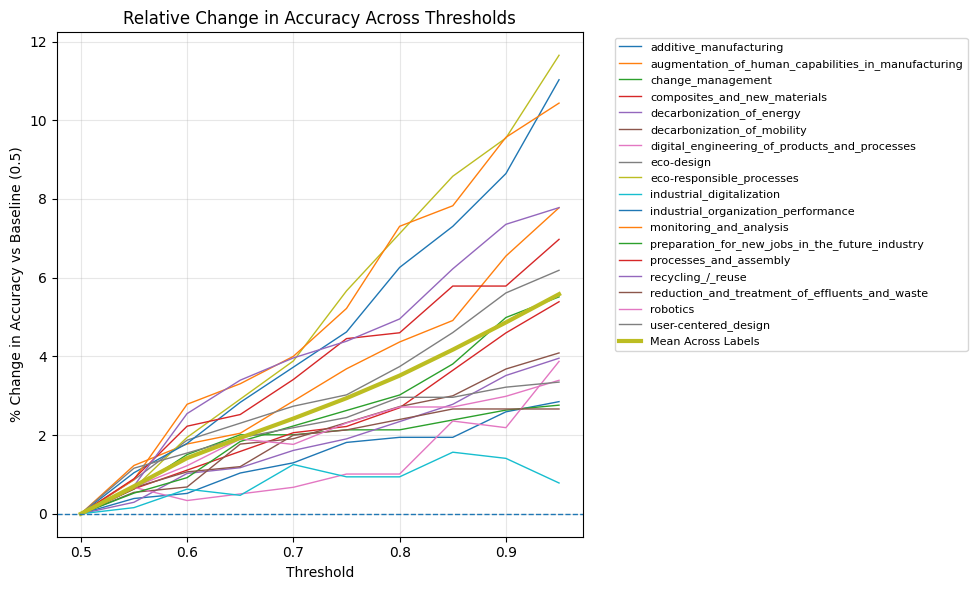

In [65]:
plot_threshold_vs_percent_change(per_label_metrics.query("model == 'Conv_Mean_null_False'"), metric='Accuracy')

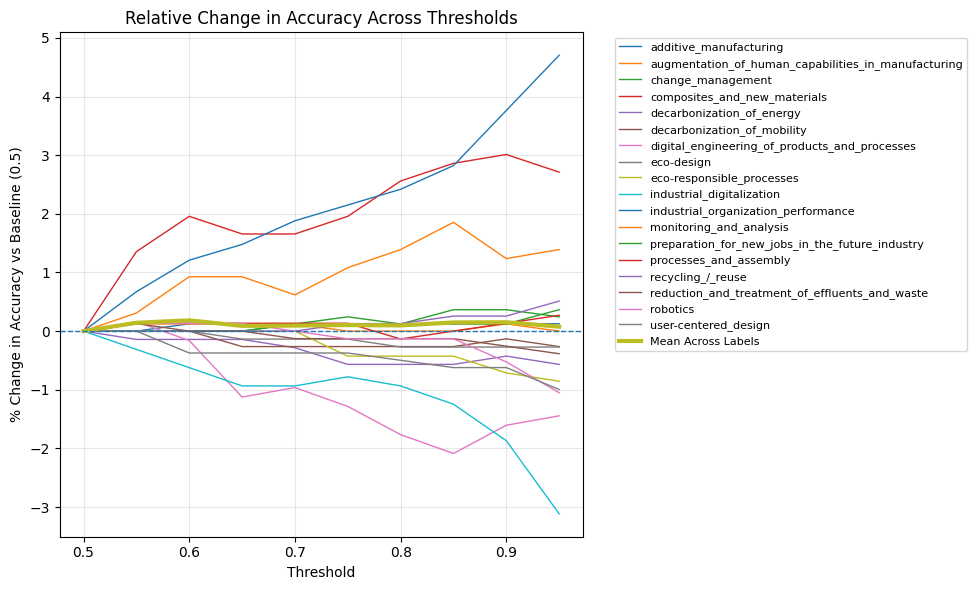

In [66]:
plot_threshold_vs_percent_change(per_label_metrics.query("model == 'Conv_Max_null_False'"), metric='Accuracy')

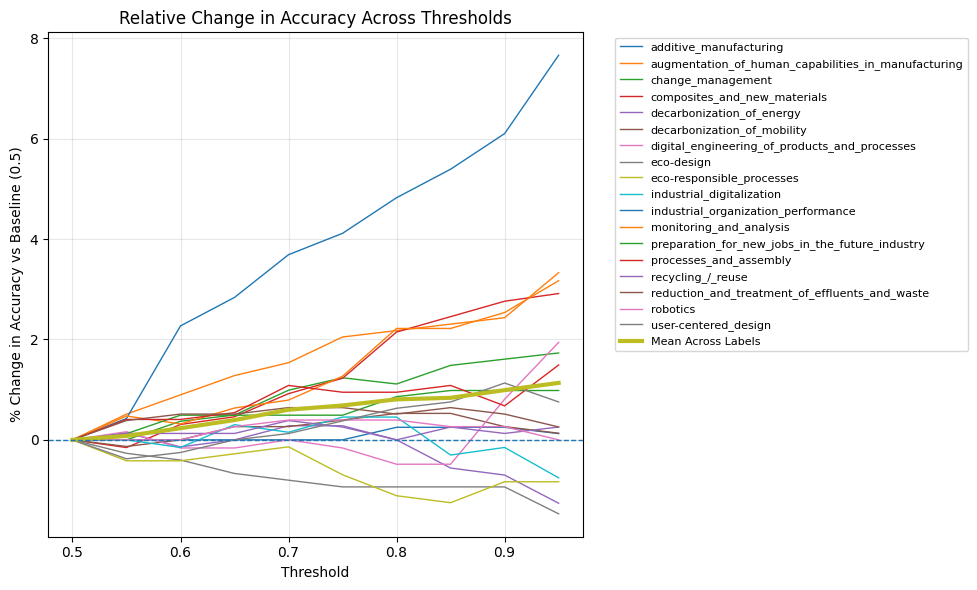

In [67]:
plot_threshold_vs_percent_change(per_label_metrics.query("model == 'Conv_Attn_null_False'"), metric='Accuracy')

- F1

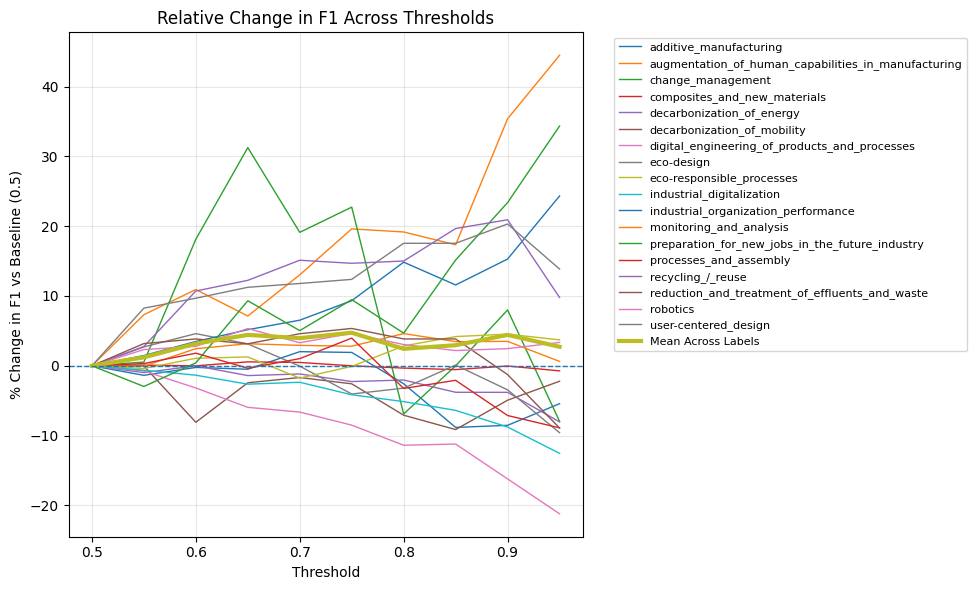

In [68]:
plot_threshold_vs_percent_change(per_label_metrics.query("model == 'Conv_Mean_null_False'"), metric='F1')

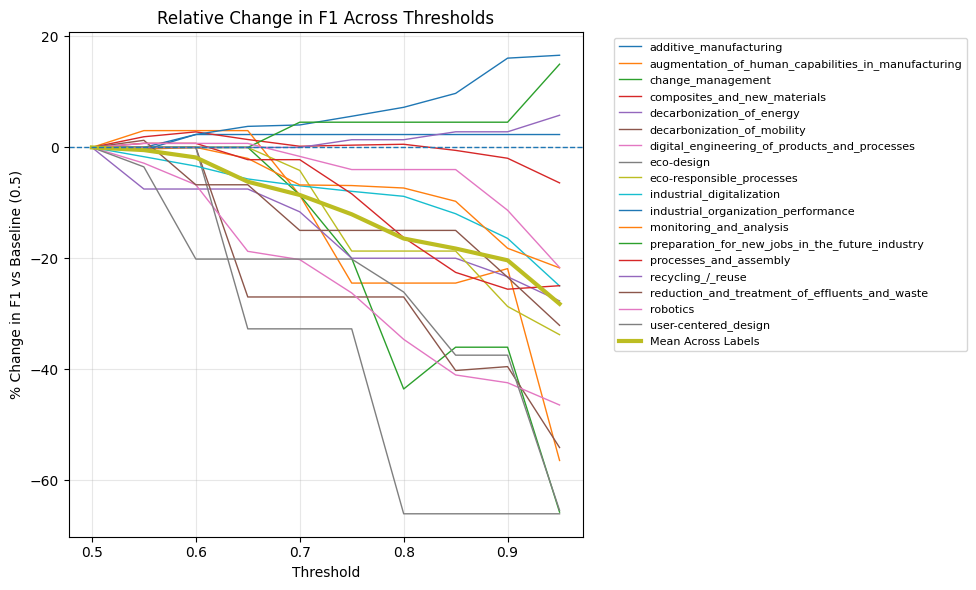

In [69]:
plot_threshold_vs_percent_change(per_label_metrics.query("model == 'Conv_Max_null_False'"), metric='F1')

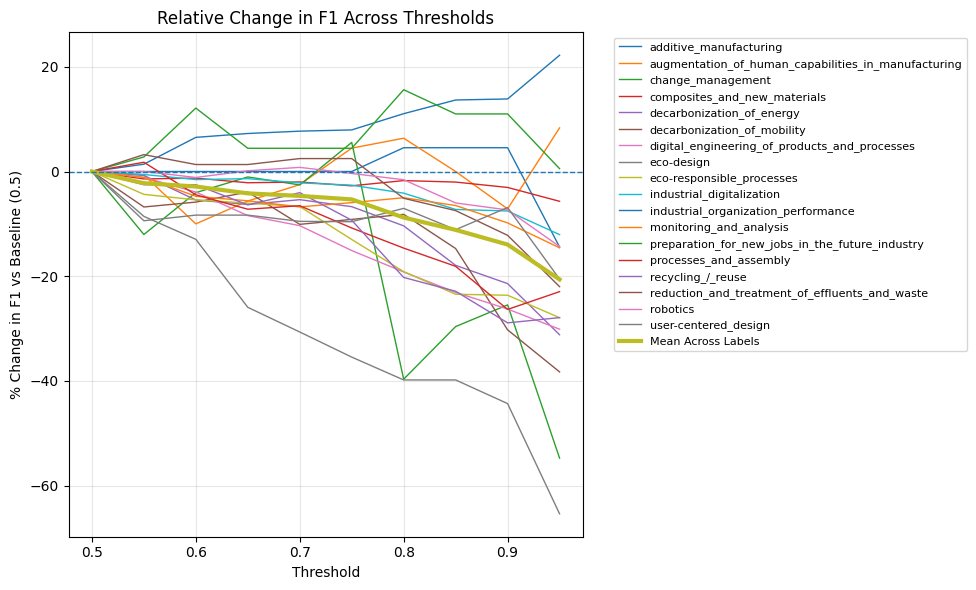

In [70]:
plot_threshold_vs_percent_change(per_label_metrics.query("model == 'Conv_Attn_null_False'"), metric='F1')

In [71]:
def plot_overall_percent_change(
    df: pd.DataFrame,
    metric: str = "F1_Micro",
    baseline_threshold: float = 0.5,
    figsize=(8, 5),
    save_path=None,
):
    """
    Plot % change of an overall metric relative to baseline threshold.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain:
        ['threshold', metric]

    metric : str
        Overall metric column name

    baseline_threshold : float
        Threshold used as baseline

    save_path : str or None
        Save figure if provided
    """

    if metric not in df.columns:
        raise ValueError(f"{metric} not found in dataframe")
    
    plt.figure(figsize=figsize)

    for model_name in df['model'].unique():

        plot_df = df.query(f"model == '{model_name}'").copy()

        baseline_row = plot_df[
            np.isclose(plot_df["threshold"], baseline_threshold)
        ]

        if len(baseline_row) == 0:
            raise ValueError(
                f"No baseline threshold={baseline_threshold} found"
            )

        baseline = baseline_row.iloc[0][metric]

        if baseline == 0:
            raise ValueError("Baseline metric is zero")

        plot_df["pct_change"] = (
            (plot_df[metric] - baseline)
            / baseline
        ) * 100

        plot_df = plot_df.sort_values("threshold")

        plt.plot(
            plot_df["threshold"],
            plot_df["pct_change"],
            linewidth=3,
            marker="o",
            label=model_name
        )

        plt.axhline(
            0,
            linestyle="--",
            linewidth=1,
        )

        plt.xlabel("Threshold", fontsize=12)
        plt.ylabel(
            f"% Change vs Baseline ({baseline_threshold})",
            fontsize=12
        )
        plt.title(
            f"Relative Change in {metric}",
            fontsize=14
        )

        plt.grid(True, alpha=0.3)

        plt.legend(frameon=False)

        plt.tight_layout()

    if save_path:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()

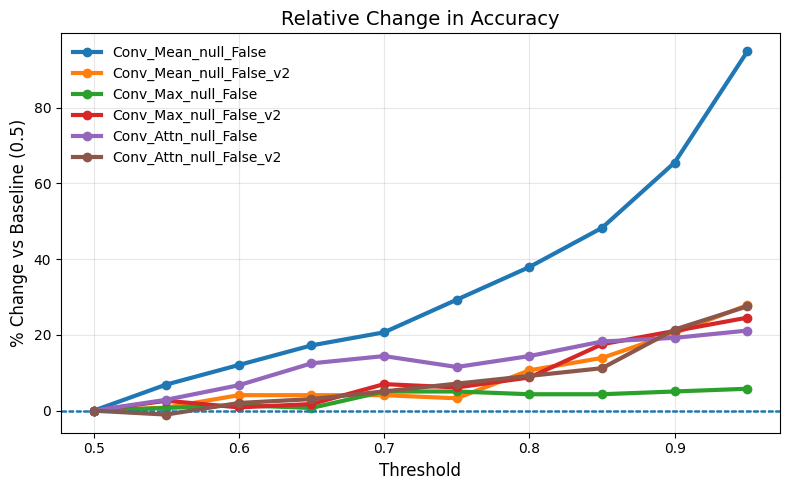

In [72]:
plot_overall_percent_change(overall_metrics, metric='Accuracy')

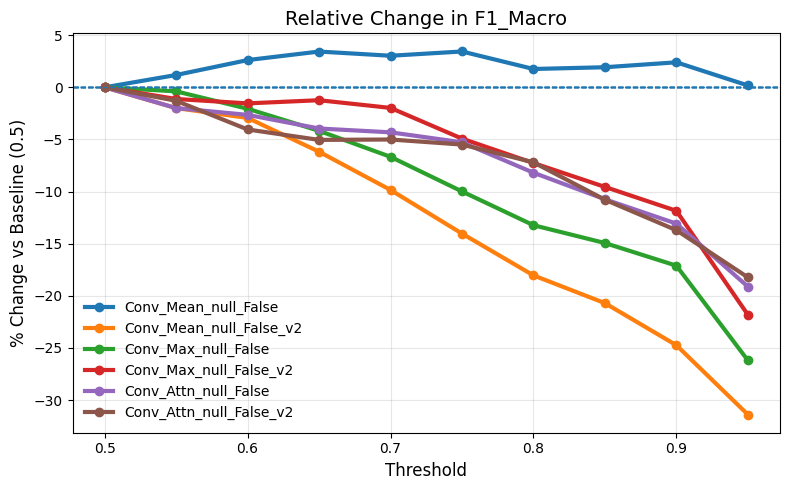

In [73]:
plot_overall_percent_change(overall_metrics, metric='F1_Macro')

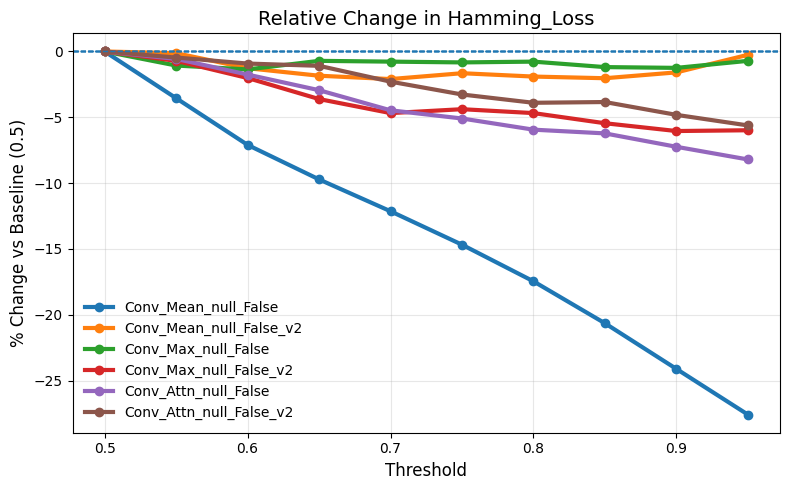

In [74]:
plot_overall_percent_change(overall_metrics, metric='Hamming_Loss')

# Communities Evaluation

In [75]:
guided = pd.Series(
    index=graph._nodes['Entity']._features['expertise_id'].tolist(),
    data=list(graph._nodes['Entity']._id2idx.keys())
)

unguided = pd.Series(
    index=graph._nodes['Entity']._features['community_proba'].argmax(dim=-1).tolist(),
    data=list(graph._nodes['Entity']._id2idx.keys())
)

In [76]:
guided = guided.groupby(guided.index).agg(list).to_frame(name='entities')
guided['size'] = guided['entities'].apply(len)
guided.head()

,entities,size
0,"[controllability, physical_machine, cable, act...",279
1,"[weight, compressive_strength, adhesive_streng...",254
2,"[energy_consumption, data_center, pue_metric, ...",199
3,"[gas_evolution_profile, temperature, peridenti...",188
4,"[global_warming_potential, life_cycle_assessme...",172


In [77]:
unguided = unguided.groupby(unguided.index).agg(list).to_frame(name='entities')
unguided['size'] = unguided['entities'].apply(len)
unguided.head()

,entities,size
0,"[glass_waste, sand, setting_time, carbon_seque...",262
1,"[controllability, industrial_deployment, paral...",226
2,"[frame, incident_heat_flux, base, simpler_mode...",233
3,"[energy_consumption, data_center, pue_metric, ...",244
4,"[models_artificial_neural_network, support_vec...",226


In [78]:
COMMUNITIES_ANNOTATION_PROMPT = """
Given a group of entities representing a cluster and a domain represented by its name and definition , 
the task is to estimate the group's alignment with that domain.

INPUT:

- Domain : {domain_name}
- Domain definition : {domain_definition}
- Entities : {entities}

IMPORTANT RULES :

- Score between 0 - 10 (0 => not aligned with the domain), (10 => Perfect alignment).
- The output should be in the following format with no additional explanation :

{{
    "score" : <number>
}}
"""

In [79]:
async def llm_classify_community(
    client : AsyncClient, 
    model : str,
    entities : List[str], 
    domain_name : str,
    domain_definition : str
) -> float:

    messages = [
        {
            "role" : "user",
            "content" : COMMUNITIES_ANNOTATION_PROMPT.format(
                domain_name=domain_name,
                domain_definition=domain_definition,
                entities='\n'.join(entities)
            )
        }
    ]

    response = await make_openai_request(
        client=client,
        model=model,
        messages=messages,
    )

    return response.unwrap().choices[0].message.content

In [80]:
async def annotate_communities(
    communities : pd.DataFrame,
    min_community_size : int,
    domains : Dict[str, str],
    llms : Dict[str, LLM],
    n_trials : int = 1,
    sample_size : int = 30,
    batch_size : int = 32
) -> pd.DataFrame:
    
    tasks = []

    for community_id, row in communities.iterrows():

        if row['size'] < min_community_size:
            continue

        num_of_samples = math.ceil(row['size'] / sample_size)

        for sample_id in range(num_of_samples):
            
            sampled_entities = random.sample(row['entities'], sample_size)

            for llm_name in llms:
                    
                for domain in domains:

                    for trial in range(n_trials):
                        
                        tasks.append({
                            "community_id" : community_id,
                            "sample_id" : sample_id,
                            "entities" : sampled_entities,
                            "model" : llm_name,
                            "domain" : domain,
                            "trial" : trial
                        })

    all_results = []

    with tqdm(total=len(tasks)) as pbar:

        for batch in batched(tasks, batch_size):

            results = await asyncio.gather(*[
                llm_classify_community(
                    client=llms[task['model']].async_client,
                    model=task['model'],
                    entities=task['entities'],
                    domain_name=task['domain'],
                    domain_definition=domains[task['domain']]
                )
                for task in batch
            ])

            all_results.extend([{ "result" : r, **task } for r, task in zip(results, batch)])

            pbar.update(len(batch))

    return pd.DataFrame(data=all_results)

In [ ]:
# communities_df = await annotate_communities(
#     communities=unguided,
#     min_community_size=30,
#     domains=domains,
#     llms={ 'deepseek-v4-flash' : env.llms['deepseek-v4-flash'] },
#     n_trials=1,
#     sample_size=30,
#     batch_size=32
# )

100%|██████████| 34902/34902 [4:24:18<00:00,  2.20it/s]  


In [206]:
guided_df = pd.read_csv('./guided_communities_deepseek-v4-flash.csv')
unguided_df = pd.read_csv('./unguided_communities_deepseek-v4-flash.csv')

In [207]:
import json

def _get_score(arg : str) -> float | None:

    try:
        return float(json.loads(arg)["score"])
    except:
        return None
    
def _entropy(x : float) -> float:
    return - math.log(x + 1e-6) * x

def entropy(x : float) -> float:
    return max(_entropy(x) + _entropy(1-x), 0.0)

In [208]:
guided_df["score"] = guided_df["result"].apply(_get_score)
guided_df = guided_df.drop(columns=['result', 'entities', 'model', 'trial']).groupby(by=['community_id', 'sample_id']).agg(list)
guided_df = pd.DataFrame(
    data=[dict(zip(a,b)) for a,b in zip(guided_df['domain'].tolist(), guided_df['score'].tolist())],
    index=guided_df.index
).reset_index()
guided_df = guided_df.drop(columns=['sample_id']).groupby('community_id').mean()
guided_df = guided_df.apply(lambda x : x/10)
guided_df = guided_df.join(guided.loc[guided_df.index])

In [209]:
unguided_df["score"] = unguided_df["result"].apply(_get_score)
unguided_df = unguided_df.drop(columns=['result', 'entities', 'model', 'trial']).groupby(by=['community_id', 'sample_id']).agg(list)
unguided_df = pd.DataFrame(
    data=[dict(zip(a,b)) for a,b in zip(unguided_df['domain'].tolist(), unguided_df['score'].tolist())],
    index=unguided_df.index
).reset_index()
unguided_df = unguided_df.drop(columns=['sample_id']).groupby('community_id').mean()
unguided_df = unguided_df.apply(lambda x : x/10)
unguided_df = unguided_df.join(unguided.loc[unguided_df.index])

In [257]:
ranges = [30, 50, 75, 100, 150, 200, 400]

entropy_df = []

for a, b in zip(ranges[:-1], ranges[1:]):
    guided_score = guided_df.query(f"(size >= {a}) and (size < {b})").drop(columns=['entities', 'size']).apply(lambda x : x.apply(entropy)).mean(axis=None)
    unguided_score = unguided_df.query(f"(size >= {a}) and (size < {b})").drop(columns=['entities', 'size']).apply(lambda x : x.apply(entropy)).mean(axis=None)
    entropy_df.append({ "range" : a , "score" : guided_score, "kind" : "guided" })
    entropy_df.append({ "range" : a , "score" : unguided_score, "kind" : "unguided" })

entropy_df = pd.DataFrame(entropy_df)

In [258]:
entropy_df

,range,score,kind
0,30,0.265400,guided
1,30,0.298466,unguided
2,50,0.301767,guided
3,50,0.315487,unguided
4,75,0.325488,guided
5,75,0.318344,unguided
6,100,0.354599,guided
7,100,0.339117,unguided
8,150,0.395099,guided
9,150,0.371999,unguided


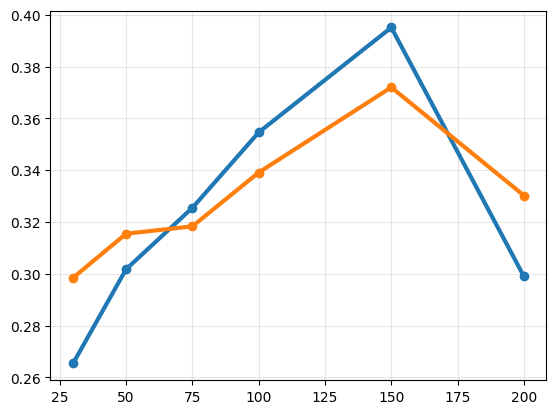

In [263]:
plt.figure()

plt.plot(
    entropy_df.query("kind == 'guided'")['range'],
    entropy_df.query("kind == 'guided'")['score'],
    linewidth=3,
    marker="o",
    label='guided'
)

# plt.axhline(
#     entropy_df.query("kind == 'guided'")['score'].mean(),
#     linestyle="--",
#     linewidth=1,
#     label='guided'
# )

plt.plot(
    entropy_df.query("kind == 'unguided'")['range'],
    entropy_df.query("kind == 'unguided'")['score'],
    linewidth=3,
    marker="o",
    label='unguided'
)

# plt.axhline(
#     entropy_df.query("kind == 'unguided'")['score'].mean(),
#     linestyle="--",
#     linewidth=1,
#     label='unguided'
# )

plt.grid(True, alpha=0.3)

In [215]:
guided_df.drop(columns=['entities', 'size']).gt(0.5).sum(axis=1).value_counts(normalize=True)

1    0.280612
0    0.253401
2    0.219388
3    0.130952
4    0.066327
5    0.037415
6    0.008503
7    0.003401
Name: proportion, dtype: float64

In [216]:
unguided_df.drop(columns=['entities', 'size']).gt(0.5).sum(axis=1).value_counts(normalize=True)

0    0.340942
1    0.329529
2    0.179743
3    0.078459
4    0.049929
5    0.015692
6    0.004280
7    0.001427
Name: proportion, dtype: float64

In [218]:
unguided_df.drop(columns=['entities', 'size']).apply(lambda x : x.apply(entropy)).mean() #.mean()

Robotics                                               0.333360
Processes and Assembly                                 0.396995
Additive Manufacturing                                 0.235797
Monitoring and Analysis                                0.522842
Eco-design                                             0.362783
Reduction and Treatment of Effluents and Waste         0.230732
Recycling / Reuse                                      0.183614
Eco-responsible Processes                              0.388253
Decarbonization of Mobility                            0.285573
Decarbonization of Energy                              0.293618
Composites and New Materials                           0.411055
Industrial Digitalization                              0.441942
Digital Engineering of Products and Processes          0.461386
Industrial Organization Performance                    0.276342
Preparation for New Jobs in the Future Industry        0.332056
Change Management                       

# Ranking Evaluation

In [91]:
graph._nodes['Entity']._features['personalized_pagerank']

tensor([3.2501e-05, 7.6881e-06, 7.0264e-04,  ..., 1.1482e-05, 1.1413e-05,
        1.1395e-05])

In [225]:
entities = pd.DataFrame(
    data=torch.stack([
        graph._nodes['Entity']._features['expertise_id'],
        graph._nodes['Entity']._features['pagerank'],
        graph._nodes['Entity']._features['personalized_pagerank'],
        graph._nodes['Entity']._features['generality_scores'],
        graph._nodes['Entity']._features['relevancy_scores'],
        graph._nodes['Entity']._features['normalized_entropy']
    ], dim=1).numpy(),
    index=list(graph._nodes['Entity']._id2idx.keys()),
    columns=['Expertise ID', 'PageRank', 'PerPageRank', 'Generality Score', 'Relevancy Score', 'Entropy'],
)

In [226]:
entities['PageRank'] = (entities['PageRank'] - entities['PageRank'].min()) / (entities['PageRank'].max() - entities['PageRank'].min())
entities['PerPageRank'] = (entities['PerPageRank'] - entities['PerPageRank'].min()) / (entities['PerPageRank'].max() - entities['PerPageRank'].min())

In [227]:
entities['PageRank - Rank'] = (1 - entities['PageRank']).rank().astype(int)
entities['PerPageRank - Rank'] = (1 - entities['PerPageRank']).rank().astype(int)

In [228]:
PROMPT_TEMPLATE = """
Given the following Entity name: {entity}

How appropriate is it, on a scale from 0 (Not appropriate at all)
to 10 (Very appropriate), to be assigned as a skill or an area of expertise
area to a researcher's profile ?

### How to think about the task :
- How well can the entity determine the field(s) associated with the researcher ?
- How useful will the entity will be if we were to match researchers profiles to a giving problem / set of problems / field ?


### Output :
Return only a number between 0 and 10. No additional explanation.
"""

In [229]:
async def llm_scoring_fn(client : AsyncClient, entity : str, model : str):

    messages = [
        {
            "role" : "user",
            "content" : PROMPT_TEMPLATE.format(entity=entity)
        }
    ]

    response = await client.chat.completions.create(
        model=model,
        messages=messages,
        temperature=0,  # No randomness
        top_p=1,  # Disable sampling
        seed=42,  # Seed
    )

    return float(response.choices[0].message.content)

In [257]:
import networkx as nx
from sknetwork.clustering import Leiden
from sknetwork.data import from_edge_list

edge_index = graph_pygeo['Entity', 'HASRELATIONWITH', 'Entity'].edge_index

sk_data = from_edge_list(
    list(
        zip(
            edge_index[0].tolist(), 
            edge_index[1].tolist()
        )
    )
)

G = nx.DiGraph()
G.add_edges_from(edge_index.t().tolist())

In [336]:
leiden = Leiden(resolution=15)
prob = torch.from_numpy(leiden.fit_predict_proba(sk_data))

In [323]:
entities['Num. Communities'] = (prob != 0.0).float().sum(-1)

In [224]:
entities['Entropy'].nlargest(100).tail(10)

company                                  2.689508
architecture                             2.687592
antenna                                  2.681926
patient                                  2.679754
computational_complexity                 2.678981
force                                    2.678981
platform                                 2.672030
fully_metallic_additive_manufacturing    2.669475
complex_system                           2.666281
chemical_composition                     2.666281
Name: Entropy, dtype: float64

In [222]:
entities['PageRank'].nsmallest(20)

processing_pathway                 0.000000
dry_aerosolization                 0.000000
high_substitution_level            0.000040
concrete_durability_property       0.000134
sustainable_protein_alternative    0.000143
tga_method                         0.000152
mk_levels_of_replacement           0.000157
activation_condition               0.000157
cement_activity                    0.000159
disintegrated_cement               0.000159
vacuum_drying                      0.000159
unexpected_event                   0.000163
thermolabile_fraction              0.000171
essential_amino_acid               0.000171
global_yield                       0.000171
bioactive_peptide                  0.000171
slag_behavior                      0.000184
hydrating_mixture                  0.000184
hydration_speed                    0.000184
activated_metakaolin_mixture       0.000184
Name: PageRank, dtype: float64

In [221]:
entities['PerPageRank'].nsmallest(20)

weight_coefficient                       0.000005
date                                     0.000005
physical_and_chemical_property           0.000006
supply_chain_multi_structural_dynamic    0.000006
elevated_temperature                     0.000006
mg_mof_cnt                               0.000006
synthetic_composite                      0.000006
consecutive_observation                  0.000006
fusion_bonding                           0.000006
resonant_frequency                       0.000006
hard_bodied_species                      0.000006
developed_die                            0.000006
forearm                                  0.000006
seismic_event                            0.000006
student_rocket_fuselage                  0.000006
control_system                           0.000006
surrogate_formulation                    0.000006
active_impedance                         0.000006
catalytic_chemical_vapor_deposition      0.000006
powder_pattern                           0.000006


In [183]:

async def evaluate_rankings_with_llm(
    client : AsyncClient,
    model : str,
    df : pd.DataFrame,
    k : int,
    score_columns : list[str],
    batch_size=32,
) -> pd.DataFrame:
    """
    Parameters
    ----------
    df : pd.DataFrame
        Index contains entity names.

    k : int
        Top-k entities per ranking metric.

    score_columns : list[str]
        Columns containing ranking scores.

    llm_scoring_fn : async callable
        async fn(entity_name) -> float

    batch_size : int
        Number of concurrent LLM requests.

    Returns
    -------
    pd.DataFrame
    """

    rows = []

    # Build all evaluation tasks
    tasks = []

    for col in score_columns:

        topk = df.nlargest(k, col)

        for rank, (entity, row) in enumerate(
            topk.iterrows(),
            start=1,
        ):
            tasks.extend([
                {
                    "ranking_metric": col,
                    "rank": rank,
                    "entity": entity,
                    "original_score": row[col],
                    "trial" : i
                }
                for i in range(5)
            ])

    pbar = tqdm(total=len(tasks), desc="LLM scoring")

    total = 0

    for start in range(0, len(tasks), batch_size):

        batch = tasks[start : start + batch_size]

        scores = await asyncio.gather(
            *[
                llm_scoring_fn(client, item["entity"], model)
                for item in batch
            ]
        )

        for item, score in zip(batch, scores):

            rows.append(
                {
                    **item,
                    "llm_score": score,
                }
            )

        pbar.update(len(batch))

        total += len(batch)

        print(f"{total}/{len(tasks)}")

    pbar.close()

    return pd.DataFrame(rows)

In [184]:
ranking_results = await evaluate_rankings_with_llm(
    client=env.llms['deepseek-v4-pro'].async_client,
    model='deepseek-v4-pro',
    df=entities,
    k=30,
    score_columns=['PageRank', 'PerPageRank'],
    batch_size=32
)

32/300


64/300


96/300


128/300


160/300


192/300


224/300


256/300


288/300








LLM scoring: 100%|██████████| 300/300 [01:30<00:00,  3.30it/s]

300/300


In [442]:
scores = ranking_results.query("ranking_metric == 'PageRank'").sort_values(by='llm_score', ascending=False)['llm_score'].to_numpy()
BASE_PP_MRR_PAGERANK = np.mean(scores / (np.arange(len(scores)) + 1))
print(BASE_PP_MRR_PAGERANK)

1.1510440016675543


In [443]:
scores = ranking_results.query("ranking_metric == 'PageRank'").sort_values(by='ranking_metric', ascending=False)['llm_score'].to_numpy()
MRR_PAGERANK = np.mean(scores / (np.arange(len(scores)) + 1)) / BASE_PP_MRR_PAGERANK
print(MRR_PAGERANK)

0.8186484220407354


In [447]:
scores = ranking_results.query("ranking_metric == 'PerPageRank'").sort_values(by='llm_score', ascending=False)['llm_score'].to_numpy()
BASE_PPP_MRR_PAGERANK = np.mean(scores / (np.arange(len(scores)) + 1))
print(BASE_PPP_MRR_PAGERANK)

1.136317471367761


In [445]:
scores = ranking_results.query("ranking_metric == 'PerPageRank'").sort_values(by='ranking_metric', ascending=False)['llm_score'].to_numpy()
MRR_PAGERANK = np.mean(scores / (np.arange(len(scores)) + 1)) / BASE_PPP_MRR_PAGERANK
print(MRR_PAGERANK)

0.6906757784006607
